# Продолжение обучения GPT-2 и reward model в Google Colab

1. Выберите **Среда выполнения → Сменить среду выполнения → GPU**.
2. Запустите ячейки сверху вниз; загрузите `rl_recsys_colab.zip` по запросу.
3. Подключите Google Drive для checkpoints. После обрыва снова запустите ячейки
   с тем же RUN_NAME: обучение продолжится с последнего сохранённого батча из `temp.pt`.

Этот ноутбук **продолжает обучение из сохранённых весов**, а не вызывает исходный
`fit`, который создаёт модели заново. Оптимизатор первого продолжения новый:
исходный архив содержит только веса. Последующие перезапуски восстанавливают
и оптимизатор, и RNG. Training идёт на GPU, validation — на CPU исходной метрикой.

Сохраняются архитектура, словарь 4096 треков и исходная validation. Расширяются
обучающая выборка и бюджет эпох. Увеличение словаря требует отдельной модели
или явного переноса embeddings с проверкой mapping. Само продолжение RM не
гарантирует улучшения: исходная модель уже переобучалась после первой эпохи.

Прежний test уже анализировался. Этот запуск — доработка на validation;
для окончательных новых исследовательских выводов нужен новый holdout.
GPU-запуск в Colab ещё не выполнен автором ноутбука; CPU-паритет и resume проверены.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import subprocess, sys
# Сохраняем установленный Colab PyTorch с его CUDA, не ставим локальные CPU requirements.
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
    'transformers==4.57.3', 'pyarrow>=17', 'pandas>=2.2',
    'scikit-learn>=1.5', 'matplotlib>=3.8'], check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.57.3', 'pyarrow>=17', 'pandas>=2.2', 'scikit-learn>=1.5', 'matplotlib>=3.8'], returncode=0)

In [3]:
import torch
assert torch.cuda.is_available(), 'Выберите GPU в настройках среды выполнения и перезапустите ячейки.'
print('PyTorch:', torch.__version__)
print('GPU:', torch.cuda.get_device_name())
print('VRAM, GiB:', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))


PyTorch: 2.11.0+cu130
GPU: Tesla T4
VRAM, GiB: 14.6


## Настройки

`EPOCHS` — дополнительные эпохи после загрузки исходных весов, максимум для данного
запуска. При resume число уже завершённых эпох учитывается автоматически: увеличение
20 → 30 продолжит с последней эпохи до 30. Новый LR, batch size или данные требуют
нового RUN_NAME. Сначала достаточно seed=42, затем повторите с SEED=2026 и новым именем.

Запуск не расширяет каталог и не устраняет слабую персонализацию RM сам по себе.
Первый полезный контроль — проверить, улучшается ли SFT при большем бюджете.


In [4]:
from pathlib import Path
RUN_NAME = 'yambda_continue_v1_seed42'
SEED = 42
TRAIN_EXAMPLES = 500_000
REWARD_EXAMPLES = 600_000
EPOCHS = 20
BATCH_SIZE = 256
SAVE_EVERY_BATCHES = 100  # Частота обновления temp.pt; best.pt — после validation.
SFT_LR = 2e-4
RUN_REWARD = False  # Включите отдельно, если хотите проверить RM на большей выборке.
REWARD_EPOCHS = 8
REWARD_LR = 1e-4

from google.colab import drive
drive.mount('/content/drive')
RUN_DIR = Path('/content/drive/MyDrive/rl_recsys_runs') / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Checkpoints:', RUN_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoints: /content/drive/MyDrive/rl_recsys_runs/yambda_continue_v1_seed42


## Загрузка проекта

Нужен новый архив `rl_recsys_colab.zip`, содержащий GPU runner. Старый
`rl_recsys_complete.zip` сохранён без изменений и не содержит этого дополнения.
Можно заранее положить ZIP в Drive и заменить ARCHIVE_PATH его путём.


In [6]:
import json
import shutil
import zipfile
import hashlib
from pathlib import Path

DRIVE_ARCHIVE = Path('/content/drive/MyDrive/rl_recsys_colab.zip')
ARCHIVE_PATH = Path('/content/rl_recsys_colab.zip')

assert DRIVE_ARCHIVE.is_file(), f'Архив не найден: {DRIVE_ARCHIVE}'

# Копируем архив из Google Drive на локальный диск Colab.
shutil.copy2(DRIVE_ARCHIVE, ARCHIVE_PATH)

def current_archive(path):
    if not path.is_file():
        return False
    try:
        with zipfile.ZipFile(path) as candidate:
            meta = json.loads(
                candidate.read('rl_recsys/reports/colab_additions_manifest.json')
            )
        return meta.get('checkpoint_format_version') == 2
    except (KeyError, ValueError, OSError, zipfile.BadZipFile):
        return False

assert current_archive(ARCHIVE_PATH), (
    'Замените /content/drive/MyDrive/rl_recsys_colab.zip '
    'обновлённым архивом с best.pt/temp.pt'
)

REFERENCE_PARENT = Path('/content/rl_reference')
REFERENCE_PARENT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    for info in archive.infolist():
        candidate = (REFERENCE_PARENT / info.filename).resolve()
        assert candidate.is_relative_to(REFERENCE_PARENT.resolve()), (
            'Некорректный путь в ZIP'
        )
    assert archive.testzip() is None, 'Архив повреждён'
    archive.extractall(REFERENCE_PARENT)

REFERENCE = REFERENCE_PARENT / 'rl_recsys'
assert (REFERENCE / 'colab_runner.py').is_file(), (
    'В архиве отсутствует colab_runner.py'
)

manifest = json.loads(
    (REFERENCE / 'reports/bundle_manifest.json').read_text()
)
for name, checksum in manifest['files'].items():
    assert hashlib.sha256(
        (REFERENCE / name).read_bytes()
    ).hexdigest() == checksum, f'Не совпадает checksum: {name}'

extras = json.loads(
    (REFERENCE / 'reports/colab_additions_manifest.json').read_text()
)
for name, checksum in extras['files'].items():
    assert hashlib.sha256(
        (REFERENCE / name).read_bytes()
    ).hexdigest() == checksum, f'Не совпадает checksum: {name}'

WORK_PARENT = Path('/content/rl_work')
PACKAGE = WORK_PARENT / 'rl_recsys'
WORK_PARENT.mkdir(parents=True, exist_ok=True)

if not PACKAGE.exists():
    shutil.copytree(REFERENCE, PACKAGE)

# Обновляем runner и тесты, сохраняя подготовленные данные и веса.
for relative in ['colab_runner.py', 'tests/test_colab_runner.py']:
    destination = PACKAGE / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(REFERENCE / relative, destination)

print('Архив в Google Drive:', DRIVE_ARCHIVE)
print('Рабочая копия:', PACKAGE)

Архив в Google Drive: /content/drive/MyDrive/rl_recsys_colab.zip
Рабочая копия: /content/rl_work/rl_recsys


## Обучающие данные

Один раз скачивается закреплённый Parquet Yambda-50M (~369 MB). Выбираются те же
пользователи и строится больше train-контекстов. Словарь и временные границы прежние.
Исходные validation/test-контексты копируются обратно после подготовки, чтобы
случайное изменение train-subsampling не изменило выборку оценки.

Кэши train/validation/catalog сохраняются в Drive и восстанавливаются после обрыва.
Это также сохраняет точные входные файлы для проверки совместимости checkpoint.
Raw Parquet в Drive не копируется. Во время обучения test не используется.


In [8]:
import json
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

import numpy as np

cfg = json.loads((REFERENCE / 'config.json').read_text())
cfg['train_examples'] = TRAIN_EXAMPLES
cfg['reward_examples'] = REWARD_EXAMPLES

(PACKAGE / 'config.json').write_text(json.dumps(cfg, indent=2) + '\n')

CACHE = RUN_DIR / 'inputs'
needed = ['train.npz', 'validation.npz', 'test.npz', 'catalog.npz']

if (CACHE / 'config.json').exists():
    assert json.loads((CACHE / 'config.json').read_text()) == cfg, (
        'Изменены данные: задайте новый RUN_NAME'
    )
    assert all((CACHE / name).is_file() for name in needed), (
        'Кэш неполный; используйте другой RUN_NAME'
    )

    for name in needed:
        shutil.copy2(CACHE / name, PACKAGE / 'artifacts' / name)

    print('Входы восстановлены из Google Drive')

else:
    subprocess.run(
        [sys.executable, '-m', 'rl_recsys.download_ranges'],
        cwd=WORK_PARENT,
        check=True,
    )
    subprocess.run(
        [sys.executable, '-m', 'rl_recsys.experiment', 'prepare'],
        cwd=WORK_PARENT,
        check=True,
    )

    with np.load(REFERENCE / 'artifacts/catalog.npz') as original:
        expected = {key: original[key] for key in original.files}

    with np.load(PACKAGE / 'artifacts/catalog.npz') as prepared:
        actual = {key: prepared[key] for key in prepared.files}

    assert expected.keys() == actual.keys()
    assert np.array_equal(expected['item_id'], actual['item_id']), (
        'Изменён словарь: старые веса несовместимы'
    )
    assert all(
        np.allclose(expected[key], actual[key], rtol=1e-6, atol=1e-7)
        for key in expected
    ), 'Изменились train-статистики'

    # В исходный архив validation.npz не вошёл.
    # Восстанавливаем исходное разбиение отдельно, не перезаписывая
    # расширенную train-выборку в PACKAGE.
    evaluation_files = ['validation.npz', 'test.npz']
    if any(
        not (REFERENCE / 'artifacts' / name).is_file()
        for name in evaluation_files
    ):
        print('Восстанавливаем исходные validation/test по исходной конфигурации...')

        with tempfile.TemporaryDirectory(prefix='rl_original_splits_') as directory:
            original_root = Path(directory)
            (original_root / 'data').mkdir()
            (original_root / 'reports').mkdir()

            (original_root / 'data/listens.parquet').symlink_to(
                (PACKAGE / 'data/listens.parquet').resolve()
            )
            shutil.copy2(
                PACKAGE / 'data/manifest.json',
                original_root / 'data/manifest.json',
            )

            subprocess.run(
                [
                    sys.executable,
                    '-c',
                    (
                        'import json, sys; '
                        'from pathlib import Path; '
                        'from rl_recsys import data; '
                        'data.ROOT = Path(sys.argv[1]); '
                        'data.prepare(json.loads(Path(sys.argv[2]).read_text()))'
                    ),
                    str(original_root),
                    str(REFERENCE / 'config.json'),
                ],
                cwd=WORK_PARENT,
                stdout=subprocess.DEVNULL,
                check=True,
            )

            # Проверяем воспроизводимость по файлам, уже имеющимся в архиве.
            for name in evaluation_files:
                destination = REFERENCE / 'artifacts' / name
                restored = original_root / 'artifacts' / name

                if destination.is_file():
                    with np.load(destination) as old, np.load(restored) as new:
                        assert set(old.files) == set(new.files)
                        assert all(
                            np.array_equal(old[key], new[key])
                            for key in old.files
                        ), f'Не удалось воспроизвести исходный {name}'
                else:
                    shutil.copy2(restored, destination)

    shutil.copy2(
        REFERENCE / 'artifacts/catalog.npz',
        PACKAGE / 'artifacts/catalog.npz',
    )

    for name in evaluation_files:
        shutil.copy2(
            REFERENCE / 'artifacts' / name,
            PACKAGE / 'artifacts' / name,
        )

    CACHE.mkdir(parents=True, exist_ok=True)
    for name in needed:
        shutil.copy2(PACKAGE / 'artifacts' / name, CACHE / name)

    # Маркер готовности записываем после успешного сохранения всех файлов.
    (CACHE / 'config.json').write_text(json.dumps(cfg, indent=2) + '\n')

    print('Данные подготовлены и сохранены в Google Drive')

print('Данные готовы; используются исходные validation/test')

Восстанавливаем исходные validation/test по исходной конфигурации...
Данные подготовлены и сохранены в Google Drive
Данные готовы; используются исходные validation/test


In [7]:
import numpy as np
cfg = json.loads((REFERENCE / 'config.json').read_text())
cfg['train_examples'] = TRAIN_EXAMPLES
cfg['reward_examples'] = REWARD_EXAMPLES
(PACKAGE / 'config.json').write_text(json.dumps(cfg, indent=2) + '\n')
CACHE = RUN_DIR / 'inputs'
needed = ['train.npz', 'validation.npz', 'test.npz', 'catalog.npz']
if (CACHE / 'config.json').exists():
    assert json.loads((CACHE / 'config.json').read_text()) == cfg, 'Изменены данные: задайте новый RUN_NAME'
    assert all((CACHE / name).exists() for name in needed), 'Неполный cache; используйте другой RUN_NAME'
    for name in needed:
        shutil.copy2(CACHE / name, PACKAGE / 'artifacts' / name)
    print('Входы восстановлены из Drive')
else:
    subprocess.run([sys.executable, '-m', 'rl_recsys.download_ranges'], cwd=WORK_PARENT, check=True)
    subprocess.run([sys.executable, '-m', 'rl_recsys.experiment', 'prepare'], cwd=WORK_PARENT, check=True)
    expected = dict(np.load(REFERENCE / 'artifacts/catalog.npz'))
    actual = dict(np.load(PACKAGE / 'artifacts/catalog.npz'))
    assert expected.keys() == actual.keys()
    assert np.array_equal(expected['item_id'], actual['item_id']), 'Изменён словарь: старые веса несовместимы'
    assert all(np.allclose(expected[k], actual[k], rtol=1e-6, atol=1e-7) for k in expected), 'Изменились train-статистики'
    shutil.copy2(REFERENCE / 'artifacts/catalog.npz', PACKAGE / 'artifacts/catalog.npz')
    for name in ['validation.npz', 'test.npz']:
        shutil.copy2(REFERENCE / 'artifacts' / name, PACKAGE / 'artifacts' / name)
    # Пишем config последним: это маркер завершённой подготовки.
    CACHE.mkdir(exist_ok=True)
    for name in needed:
        shutil.copy2(PACKAGE / 'artifacts' / name, CACHE / name)
    (CACHE / 'config.json').write_text(json.dumps(cfg, indent=2) + '\n')
print('Данные готовы; validation/test сохранены исходными')


FileNotFoundError: [Errno 2] No such file or directory: '/content/rl_reference/rl_recsys/artifacts/validation.npz'

## Проверки адаптации

В том числе проверяется, что продолжение после сохранённой эпохи совпадает
с непрерывным обучением на маленькой CPU-задаче. При доступной CUDA дополнительно
проверяется GPU forward. Сами weights исходного решения не перезаписываются.


In [9]:
subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'rl_recsys/tests', '-v'],
               cwd=WORK_PARENT, check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'unittest', 'discover', '-s', 'rl_recsys/tests', '-v'], returncode=0)

## Продолжение SFT

`best.pt` включает исходный checkpoint как кандидата эпохи 0. Если продолжение
ухудшит validation NDCG, исходные веса останутся лучшими. `temp.pt` содержит текущее состояние: веса, optimizer, RNG, порядок примеров,
эпоху и позицию следующего батча. Он обновляется каждые `SAVE_EVERY_BATCHES`
батчей, перед validation и после каждой эпохи. После обрыва продолжение идёт
с этой позиции, без повторения всей эпохи. Старый `last.pt` автоматически читается
при первом запуске новой версии. Файлы сохраняются в папке RUN_DIR в Google Drive.


In [10]:
SFT_OUTPUT = RUN_DIR / f'sft_seed{SEED}'
subprocess.run([sys.executable, '-u', '-m', 'rl_recsys.colab_runner',
    '--stage', 'sft', '--seed', str(SEED), '--epochs', str(EPOCHS),
    '--batch-size', str(BATCH_SIZE), '--learning-rate', str(SFT_LR),
    '--save-every-batches', str(SAVE_EVERY_BATCHES),
    '--device', 'cuda', '--output', str(SFT_OUTPUT)], cwd=WORK_PARENT, check=True)


CompletedProcess(args=['/usr/bin/python3', '-u', '-m', 'rl_recsys.colab_runner', '--stage', 'sft', '--seed', '42', '--epochs', '20', '--batch-size', '256', '--learning-rate', '0.0002', '--save-every-batches', '100', '--device', 'cuda', '--output', '/content/drive/MyDrive/rl_recsys_runs/yambda_continue_v1_seed42/sft_seed42'], returncode=0)

,epoch,validation_score,train_loss
0,0,0.021850,NaN
1,1,0.024637,6.537830
2,2,0.026301,6.354562
3,3,0.028591,6.251509
4,4,0.029488,6.175983
5,5,0.030432,6.115773
6,6,0.030040,6.064311
7,7,0.030449,6.018947
8,8,0.030527,5.978497
9,9,0.029828,5.941741


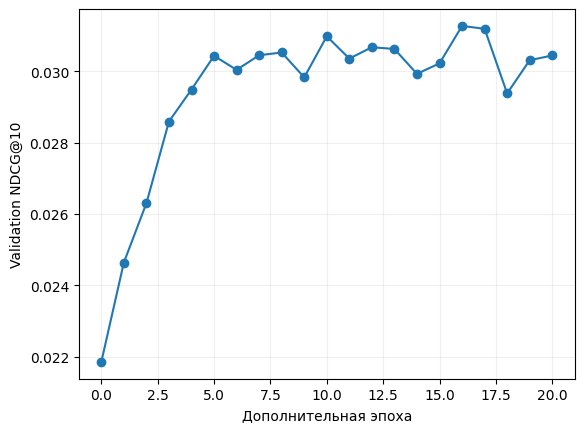

Лучшие веса: /content/drive/MyDrive/rl_recsys_runs/yambda_continue_v1_seed42/sft_seed42/best.pt
Checkpoint для продолжения: /content/drive/MyDrive/rl_recsys_runs/yambda_continue_v1_seed42/sft_seed42/temp.pt


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
history = pd.read_json(SFT_OUTPUT / 'history.json')
display(history)
plt.plot(history.epoch, history.validation_score, marker='o')
plt.xlabel('Дополнительная эпоха'); plt.ylabel('Validation NDCG@10'); plt.grid(alpha=.2)
plt.show()
print('Лучшие веса:', SFT_OUTPUT / 'best.pt')
print('Checkpoint для продолжения:', SFT_OUTPUT / 'temp.pt')


## Необязательное продолжение reward model

Включается флагом RUN_REWARD. Это та же архитектура, больше train-примеров и
меньший LR; оно может не улучшить RM. Выбор эпохи — по validation MSE/Brier,
с исходной RM как кандидатом эпохи 0. Независимое усиление истории пользователя
потребует изменения признаков/архитектуры и отдельного эксперимента.


In [12]:
if RUN_REWARD:
    REWARD_OUTPUT = RUN_DIR / f'reward_seed{SEED}'
    subprocess.run([sys.executable, '-u', '-m', 'rl_recsys.colab_runner',
        '--stage', 'reward', '--seed', str(SEED), '--epochs', str(REWARD_EPOCHS),
        '--batch-size', str(BATCH_SIZE), '--learning-rate', str(REWARD_LR),
        '--save-every-batches', str(SAVE_EVERY_BATCHES),
        '--device', 'cuda', '--output', str(REWARD_OUTPUT)], cwd=WORK_PARENT, check=True)
    display(pd.read_json(REWARD_OUTPUT / 'history.json'))
    print('Лучшие веса RM:', REWARD_OUTPUT / 'best.pt')
    print('Checkpoint RM:', REWARD_OUTPUT / 'temp.pt')
else:
    print('RM пропущена: RUN_REWARD=False')


RM пропущена: RUN_REWARD=False


## Скачать результаты

Этот ноутбук продолжает SFT и, при включении, RM. Он **не запускает новый RL автоматически**.
Следующий этап — сравнить validation, затем отдельно обучить RL от нового baseline,
добавив continued-SFT/reranking контроль и новый временной holdout.

Передайте обратно архив результатов: в нём best/temp checkpoints, кривые, настройки
и точные подготовленные входы. Для resume достаточно сохранить папку в Drive и
повторить ноутбук с теми же настройками. Старый REPORT относится к исходному запуску.


In [13]:
archive_path = shutil.make_archive('/content/rl_colab_results', 'zip', RUN_DIR)
print(archive_path)
from google.colab import files
files.download(archive_path)


/content/rl_colab_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>